In [1]:
## Import libraries
## Numerical arrays and linear algebra
import numpy as np
## Plotting and visualization
import matplotlib.pyplot as plt
## Geometry and mesh operations
import gmsh

# Seminar. Steady-State Heat Conduction in a Plate: The Finite Element Method in Python

**Topic:** Two-dimensional steady-state heat conduction, linear triangular finite elements, matrix assembly, and boundary conditions of the first, second, and third kinds.

**Objective:** Compute the temperature field in a square plate.

**Outcome:** A compact finite element solver implemented with `NumPy`.

**Prerequisites:** NumPy arrays, loops, linear systems, and the preceding seminar on planar trusses.

**Estimated duration:** 90–120 minutes, including exercises. For a shorter class, the convergence study and the additional case may be assigned as independent work.

**Learning objectives:**
1. Derive a matrix system from the governing differential equation.
2. Generate a triangular mesh and understand node indexing.
3. Compute an element matrix and assemble the global matrix.
4. Apply convection, prescribed heat flux, and prescribed temperature boundary conditions.


## 1. Problem Formulation

Consider a square plate with $L_x=L_y=5$ mm and constant thermal conductivity $\lambda=45$ W/(m·K). We solve a **steady-state** problem **without internal heat generation**:

$$
\nabla\cdot(\lambda\nabla T)=0.
$$

Here, $T(x,y)$ is the temperature and $\lambda$ is the thermal conductivity. The plate is represented by a two-dimensional model of thickness $t$, which is included explicitly in the integrals.

**Sign convention:** the applied heat flux $q$ is positive when heat is supplied to the body. Fourier's law is $\mathbf q=-\lambda\nabla T$. The outward normal heat flux used in the table is $q_{\mathrm{out}}=\mathbf q\cdot\mathbf n=-q$.

| Boundary condition | Physical interpretation | Boundary equation |
|---|---|---|
| First kind (Dirichlet) | Prescribed temperature | $T=T_b$ |
| Second kind (Neumann) | Prescribed outward heat flux | $-\lambda\nabla T\cdot\mathbf n=q_{\mathrm{out}}$ |
| Third kind (Robin) | Heat exchange with the surroundings | $-\lambda\nabla T\cdot\mathbf n=h(T-T_\infty)$ |


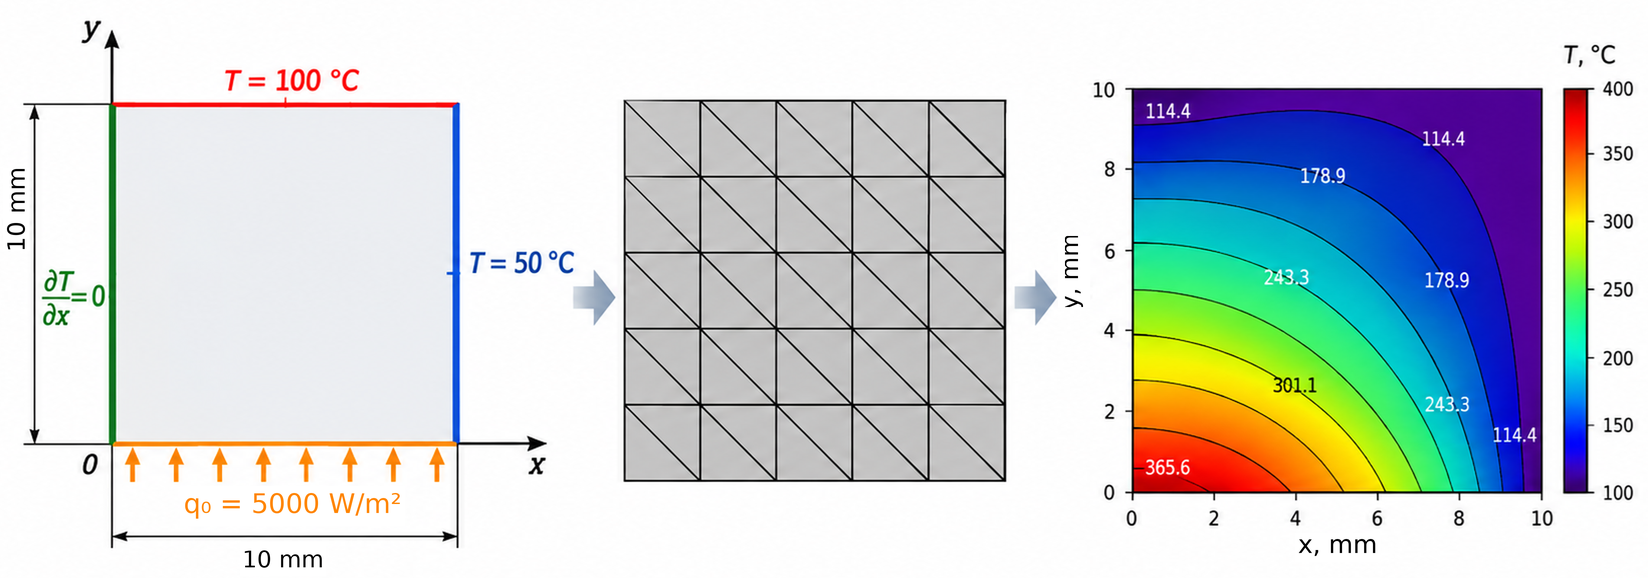


Geometry of the computational domain and material properties


In [2]:
lam = 45.0                   # W/(m·K): thermal conductivity
th = 1e-3                    # m: plate thickness


## 2. Geometry and Finite Element Mesh

The plate geometry is imported from a STEP geometry file, and a finite element mesh is then generated using `Gmsh`.

The geometry is imported **without predefined boundary labels**: no identifiers or physical groups have been assigned to the individual sides for use in boundary conditions.

Because the geometry is a simple rectangular plate, its boundaries can be identified from the node coordinates and element connectivity.

The data required for subsequent calculations are extracted from the mesh and stored as follows:

- `pnts[i] = [x_i, y_i]` — coordinates of node $i$;
- `elms[e] = [i, j, k]` — indices of the three nodes of element $e$.

These arrays will be used to compute element conductivity matrices, assemble the global system of equations, and identify the boundary segments on which boundary conditions are imposed.



**Initializing and Finalizing Gmsh**

**Gmsh** is a standalone application for geometry processing and finite element mesh generation. Here, it is controlled directly from **JupyterLab** through the `gmsh` Python library, without using the graphical interface.

Initialize Gmsh before using its API:

```python
gmsh.initialize()
```

This command initializes the Gmsh environment for geometry import, mesh generation, and extraction of finite element data.

After completing all geometry and mesh operations, finalize Gmsh:

```python
gmsh.finalize()
```

The node coordinates `pnts` and element connectivity `elms` already stored in NumPy arrays remain available for subsequent calculations.

**Important:** `gmsh.initialize()` and `gmsh.finalize()` delimit a Gmsh session. Reinitializing Gmsh without finalizing the preceding session may cause errors. The execution order of JupyterLab cells must therefore be observed.


In [3]:
## Initialize geometry import and mesh preparation
gmsh.initialize()
geom_path = '_geom/geom.stp'
mesh_path = '_geom/mesh.msh'
gmsh.option.setNumber("Geometry.OCCImportLabels", 1)            # Import geometric entity labels 

Generating the mesh from the geometry


In [4]:
gmsh.open(geom_path)
# Element size
gmsh.option.setNumber("Mesh.MeshSizeMin", 0.5)
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.5)
# Generate a two-dimensional mesh
gmsh.model.mesh.generate(2)
gmsh.write(mesh_path)

Info    : Reading '_geom/geom.stp'...
Info    :  - Label 'Shapes/Surface' (2D)
Info    :  - Color (0.560784, 0.686275, 0.560784) (2D & Surfaces)
Info    : Done reading '_geom/geom.stp'
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000207083s, CPU 0.000199s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00427571s, CPU 0.004269s)
Info    : 144 nodes 290 elements
Info    : Writing '_geom/mesh.msh'...
Info    : Done writing '_geom/mesh.msh'


Reading the mesh from the generated file


In [5]:
# Read the generated mesh
gmsh.open(mesh_path)

Info    : Reading '_geom/mesh.msh'...
Info    : 9 entities
Info    : 144 nodes
Info    : 290 elements
Info    : Done reading '_geom/mesh.msh'


The mesh entries in the corresponding section of the file are stored sequentially rather than in the array layout required here. After retrieving these data, reshape them into a convenient form for further processing.


In [6]:
node_tags, pnts, _ = gmsh.model.mesh.getNodes()
pnts = pnts.reshape(-1, 3)                            
# Retain x and y for the two-dimensional problem
pnts = pnts[:, :2]*1e-3

In [7]:
_, _, elms = gmsh.model.mesh.getElements(2)
elms = elms[0].reshape(-1, 3)

`elms` contains node tags starting at `1`, whereas indexing the `pnts` array requires zero-based indices. We therefore subtract 1.


In [8]:
elms = elms -1

In [9]:
# Store the numbers of nodes and elements for subsequent loops
nn = len(pnts)
ne = len(elms) 

In [10]:
# Finalize Gmsh
gmsh.finalize()

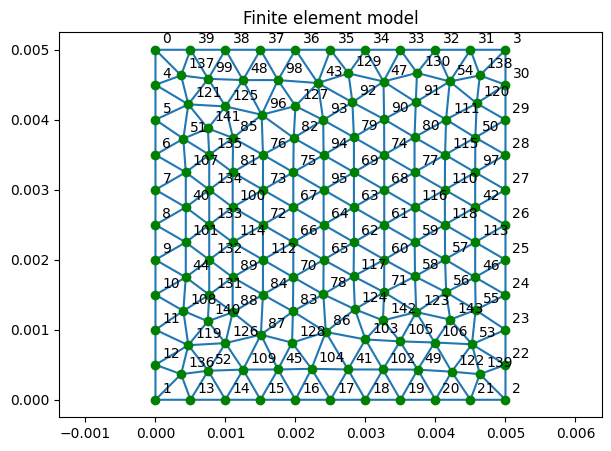

In [11]:
fig, ax = plt.subplots(figsize=(7,5))
plt.title('Finite element model')
ax.triplot(pnts[:,0]  , pnts[:,1]  , elms)
ax.plot(pnts[:,0], pnts[:,1], 'go', lw=1.0)
texts = [ax.text(pnts[i,0]+1e-4, pnts[i,1]+1e-4, '%s' %i) for i in range(nn)]
plt.axis('equal')
plt.show()

### Inspect the Node Indices of One Element

**Exercise:** Determine the coordinates of all three nodes of element 0.


In [12]:
eid = 0
node_ids = elms[eid]
coords = pnts[node_ids]

print('Element:', eid)
print('Node indices:', node_ids)
print('Coordinates, mm:\n', coords * 1e3)

Element: 0
Node indices: [ 41 103  86]
Coordinates, mm:
 [[2.75       0.4330127 ]
 [2.99969582 0.86156268]
 [2.43293901 0.96859013]]


## 3. Properties of an Individual Element

Consider the **linear triangular finite element** $e_i$ shown below. Its vertices are nodes $i$, $j$, and $m$, with coordinates:

$$
i(x_i,y_i), \qquad j(x_j,y_j), \qquad m(x_m,y_m).
$$

The unknown nodal temperatures are $T_i$, $T_j$, and $T_m$.


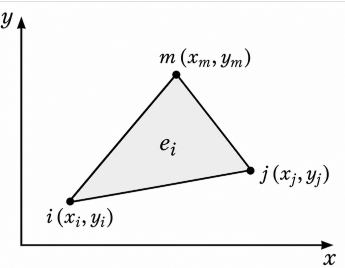



### Approximation of the Temperature Field

Within a linear triangular finite element, the temperature is approximated in terms of its values at the three nodes:

$$
T(x,y)=N_i(x,y)T_i+N_j(x,y)T_j+N_m(x,y)T_m,
$$

where $N_i$, $N_j$, and $N_m$ are the **shape functions**, which determine the contribution of each nodal temperature to the temperature at an arbitrary point within the element.

Each shape function is equal to one at its own node and zero at the other nodes of the element. For example:

$$
N_i(x_i,y_i)=1,\qquad
N_i(x_j,y_j)=N_i(x_m,y_m)=0.
$$

In matrix notation, this approximation is written as:

$$
T(x,y)=[N]\{T\}_e,
$$

where

$$
[N]=
\begin{pmatrix}
N_i & N_j & N_m
\end{pmatrix},
\qquad
\{T\}_e=
\begin{pmatrix}
T_i\\
T_j\\
T_m
\end{pmatrix}.
$$

For a linear triangular element, the shape functions are linear in $x$ and $y$. Consequently, the temperature varies linearly within the element, and its spatial derivatives are constant.

### Element Geometry

The node coordinates and the area of the triangular element are required to determine the shape functions and subsequently derive the element conductivity matrix.

Consider two vectors along the sides of the triangle, sharing vertex $i$:

$$
\mathbf{r}_{ij}=
\begin{pmatrix}
x_j-x_i\\
y_j-y_i
\end{pmatrix},
\qquad
\mathbf{r}_{im}=
\begin{pmatrix}
x_m-x_i\\
y_m-y_i
\end{pmatrix}.
$$

The magnitude of their cross product is the area of the parallelogram they span. The area of the triangle is half this value:

$$
A_e=\frac12
\left|
(x_j-x_i)(y_m-y_i)
-
(x_m-x_i)(y_j-y_i)
\right|.
$$

This expression can also be written using a determinant:

$$
\boxed{
A_e=\frac12
\left|
\det
\begin{pmatrix}
1 & x_i & y_i\\
1 & x_j & y_j\\
1 & x_m & y_m
\end{pmatrix}
\right|
}
$$

Denote the determinant by $\Delta_e$:

$$
\Delta_e=
\det
\begin{pmatrix}
1 & x_i & y_i\\
1 & x_j & y_j\\
1 & x_m & y_m
\end{pmatrix}.
$$

Then:

$$
A_e=\frac{|\Delta_e|}{2}.
$$

**The sign of the determinant depends on the node ordering:** $\Delta_e>0$ for counterclockwise ordering and $\Delta_e<0$ for clockwise ordering. The geometric area $A_e$ is always positive.

### Derivation of the Shape Functions

The shape functions of a linear triangular element are:

$$
N_i(x,y)=\frac{a_i+b_ix+c_iy}{\Delta_e},
$$

$$
N_j(x,y)=\frac{a_j+b_jx+c_jy}{\Delta_e},
$$

$$
N_m(x,y)=\frac{a_m+b_mx+c_my}{\Delta_e}.
$$

The coefficients $a_i$, $a_j$, and $a_m$ are determined from the node coordinates:

$$
\mathbf a=
\begin{pmatrix}
x_jy_m-x_my_j\\
x_my_i-x_iy_m\\
x_iy_j-x_jy_i
\end{pmatrix}.
$$

Similarly, define the vectors of geometric coefficients:

$$
\mathbf b=
\begin{pmatrix}
y_j-y_m\\
y_m-y_i\\
y_i-y_j
\end{pmatrix},
\qquad
\mathbf c=
\begin{pmatrix}
x_m-x_j\\
x_i-x_m\\
x_j-x_i
\end{pmatrix}.
$$

The denominator $\Delta_e$ ensures that the interpolation conditions are satisfied: each shape function equals one at its own node and zero at the other nodes.

Because the shape functions are linear, their derivatives are constant within the element:

$$
\frac{\partial N_i}{\partial x}=\frac{b_i}{\Delta_e},
\qquad
\frac{\partial N_i}{\partial y}=\frac{c_i}{\Delta_e}.
$$

Analogous expressions apply to nodes $j$ and $m$.

The temperature derivatives can therefore be expressed in terms of the nodal values:

$$
\frac{\partial T}{\partial x}
=
\frac{1}{\Delta_e}
\left(
b_iT_i+b_jT_j+b_mT_m
\right),
$$

$$
\frac{\partial T}{\partial y}
=
\frac{1}{\Delta_e}
\left(
c_iT_i+c_jT_j+c_mT_m
\right).
$$

Introduce the **matrix of element geometric coefficients**:

$$
\mathbf H=
\begin{pmatrix}
b_i & b_j & b_m\\
c_i & c_j & c_m
\end{pmatrix}.
$$

Both temperature derivatives can then be combined into a single matrix expression:

$$
\boxed{
\nabla T=
\begin{pmatrix}
\dfrac{\partial T}{\partial x}\\[6pt]
\dfrac{\partial T}{\partial y}
\end{pmatrix}
=
\frac{1}{\Delta_e}\mathbf H\{T\}_e
}
$$

Thus, **the temperature gradient is constant within each linear triangular element**.

For counterclockwise node ordering, $\Delta_e=2A_e$. In general, the sign of the determinant must be retained when evaluating the derivatives.

### Derivation of the Element Conductivity Matrix from the Functional

For steady-state heat conduction without internal heat generation, the solution can be obtained from the **stationarity condition of the functional**:

$$
\Phi(T)=
\frac{\lambda t}{2}
\int_S
\left[
\left(\frac{\partial T}{\partial x}\right)^2+
\left(\frac{\partial T}{\partial y}\right)^2
\right]dS
-
t\int_{\Gamma_2}q_0T\,dL
+
\frac{\alpha t}{2}
\int_{\Gamma_3}(T-T_\infty)^2\,dL.
$$

Here:

- $S$ is the plate domain;
- $t$ is the plate thickness, assumed constant;
- $\lambda$ is the thermal conductivity;
- $\Gamma_2$ is the boundary segment with prescribed heat flux;
- $q_0$ is the prescribed heat flux density;
- $\Gamma_3$ is the boundary segment with convective heat transfer;
- $\alpha$ is the convective heat transfer coefficient;
- $T_\infty$ is the ambient temperature.

**Sign convention:** positive heat flux $q_0$ is directed into the plate. The corresponding term in the functional therefore has a negative sign.

The functional contains three contributions:

1. **The first term** represents heat conduction within the plate.
2. **The second term** accounts for prescribed heat flux (Neumann boundary conditions).
3. **The third term** describes convective heat transfer (Robin boundary conditions).

Dirichlet boundary conditions prescribe the temperature on the corresponding boundary segment:

$$
T|_{\Gamma_1}=T_\Gamma.
$$

They do not introduce an additional integral into the functional. Instead, they constrain the admissible temperature fields when determining its stationary value.

### Formulation of the Element Conductivity Matrix

Consider the first term of the functional, representing heat conduction within a single finite element:

$$
\Phi_e^{(\lambda)}=
\frac{\lambda t}{2}
\int_{A_e}
(\nabla T)^{\mathsf T}(\nabla T)\,dA.
$$

Substitute the expression derived above for the temperature gradient:

$$
\nabla T=\frac{1}{\Delta_e}\mathbf H\{T\}_e.
$$

Then:

$$
\Phi_e^{(\lambda)}=
\frac{\lambda t}{2\Delta_e^2}
\int_{A_e}
\{T\}_e^{\mathsf T}
\mathbf H^{\mathsf T}\mathbf H
\{T\}_e\,dA.
$$

For a linear triangular element, $\mathbf H$ is constant throughout the element. The nodal temperature vector $\{T\}_e$ is also independent of the integration coordinates.

Integration therefore reduces to multiplication by the element area:

$$
\Phi_e^{(\lambda)}=
\frac{\lambda t A_e}{2\Delta_e^2}
\{T\}_e^{\mathsf T}
\mathbf H^{\mathsf T}\mathbf H
\{T\}_e.
$$

Using

$$
\Delta_e^2=4A_e^2,
$$

we obtain:

$$
\Phi_e^{(\lambda)}=
\frac{\lambda t}{8A_e}
\{T\}_e^{\mathsf T}
\mathbf H^{\mathsf T}\mathbf H
\{T\}_e.
$$

This expression is a quadratic form:

$$
\Phi_e^{(\lambda)}=
\frac12
\{T\}_e^{\mathsf T}
\mathbf K_e
\{T\}_e.
$$

Comparing these expressions gives the **conductivity matrix of an individual triangular finite element**:

$$
\boxed{
\mathbf K_e=
\frac{\lambda t}{4A_e}
\mathbf H^{\mathsf T}\mathbf H
}
$$


The resulting element matrix is $3\times3$ and depends on the node coordinates, thermal conductivity, and plate thickness.

### Stationarity Condition of the Functional

In the finite element method, the continuous temperature field is approximated using a finite number of nodal temperatures. After substituting the shape functions, the functional becomes a function of these unknowns:

$$
\Phi=\Phi(T_1,T_2,\ldots,T_n).
$$

The **stationarity condition** requires that the first derivative with respect to every unknown nodal temperature be zero:

$$
\boxed{
\frac{\partial\Phi}{\partial T_i}=0,
\qquad i=1,2,\ldots,n.
}
$$

Differentiation is performed only with respect to unknown temperatures; values prescribed by Dirichlet boundary conditions are held fixed.

After forming the element matrices and vectors, the functional for the entire system can be written as:

$$
\Phi=
\frac12\mathbf T^{\mathsf T}\mathbf K\mathbf T
-
\mathbf T^{\mathsf T}\mathbf F+C,
$$

where $\mathbf K$ is the global matrix, $\mathbf F$ is the thermal load vector, and $C$ is independent of the unknown temperatures.

Using the symmetry of $\mathbf K$ gives:

$$
\frac{\partial\Phi}{\partial\mathbf T}
=
\mathbf K\mathbf T-\mathbf F.
$$

The stationarity condition therefore yields a system of linear algebraic equations:

$$
\boxed{
\mathbf K\mathbf T=\mathbf F.
}
$$

Thus, **the global finite element system follows by setting the derivatives of the functional with respect to the unknown nodal temperatures to zero**.

**Important:** although the sign of the determinant depends on the node ordering, the expression for the element matrix in terms of the positive area $A_e$ is valid for either ordering.

### Transition to the Global System of Equations

The element matrix $\mathbf K_e$ obtained above describes heat conduction within a single triangular element.

To compute the temperature field of the entire plate, the element matrices must be assembled into the **global conductivity matrix**.

Stationarity of the functional with respect to the unknown nodal temperatures yields the system of linear algebraic equations:

$$
\mathbf K_{\mathrm{glob}}\mathbf T=
\mathbf F_{\mathrm{glob}}.
$$

Assembly of the global system includes contributions from heat conduction and boundary conditions.

- **Neumann boundary conditions** contribute additional terms to the thermal load vector $\mathbf F_{\mathrm{glob}}$.
- **Robin boundary conditions** contribute additional terms to both $\mathbf K_{\mathrm{glob}}$ and $\mathbf F_{\mathrm{glob}}$.

The following sections describe the assembly of the global matrix from element matrices and the subsequent application of boundary conditions.


Their mathematical implementation is developed in detail below.


In [13]:
def get_kel(element, km, th=th):
    i , j , m = element
    xi, yi = pnts[i]
    xj, yj = pnts[j]
    xm, ym = pnts[m]
    area = 0.5 * abs((xj-xi)*(ym-yi) - (yj-yi)*(xm-xi))
    b = np.array([yj-ym, ym-yi, yi-yj])
    c = np.array([xm-xj, xi-xm, xj-xi])
    H = np.array([b, c])
    Kel = km * th / (4 * area) * (H.T @ H)                     # Matrix multiplication, not elementwise multiplication
    return Kel   

In [14]:
Ke0 = get_kel(elms[0], km = lam)
print('Element conductivity matrix:\n', Ke0)
print('Symmetric:', np.allclose(Ke0, Ke0.T))
print('Row sums (expected to be close to zero):', Ke0.sum(axis=1))

Element conductivity matrix:
 [[ 0.02776266 -0.01978022 -0.00798244]
 [-0.01978022  0.03232785 -0.01254763]
 [-0.00798244 -0.01254763  0.02053007]]
Symmetric: True
Row sums (expected to be close to zero): [-1.73472348e-18 -5.20417043e-18  3.46944695e-18]


## 4. Assembly of the Global Matrix

For each element, identify its three global node indices and add the entries of $K_e$ to the corresponding positions in the global matrix $K$.


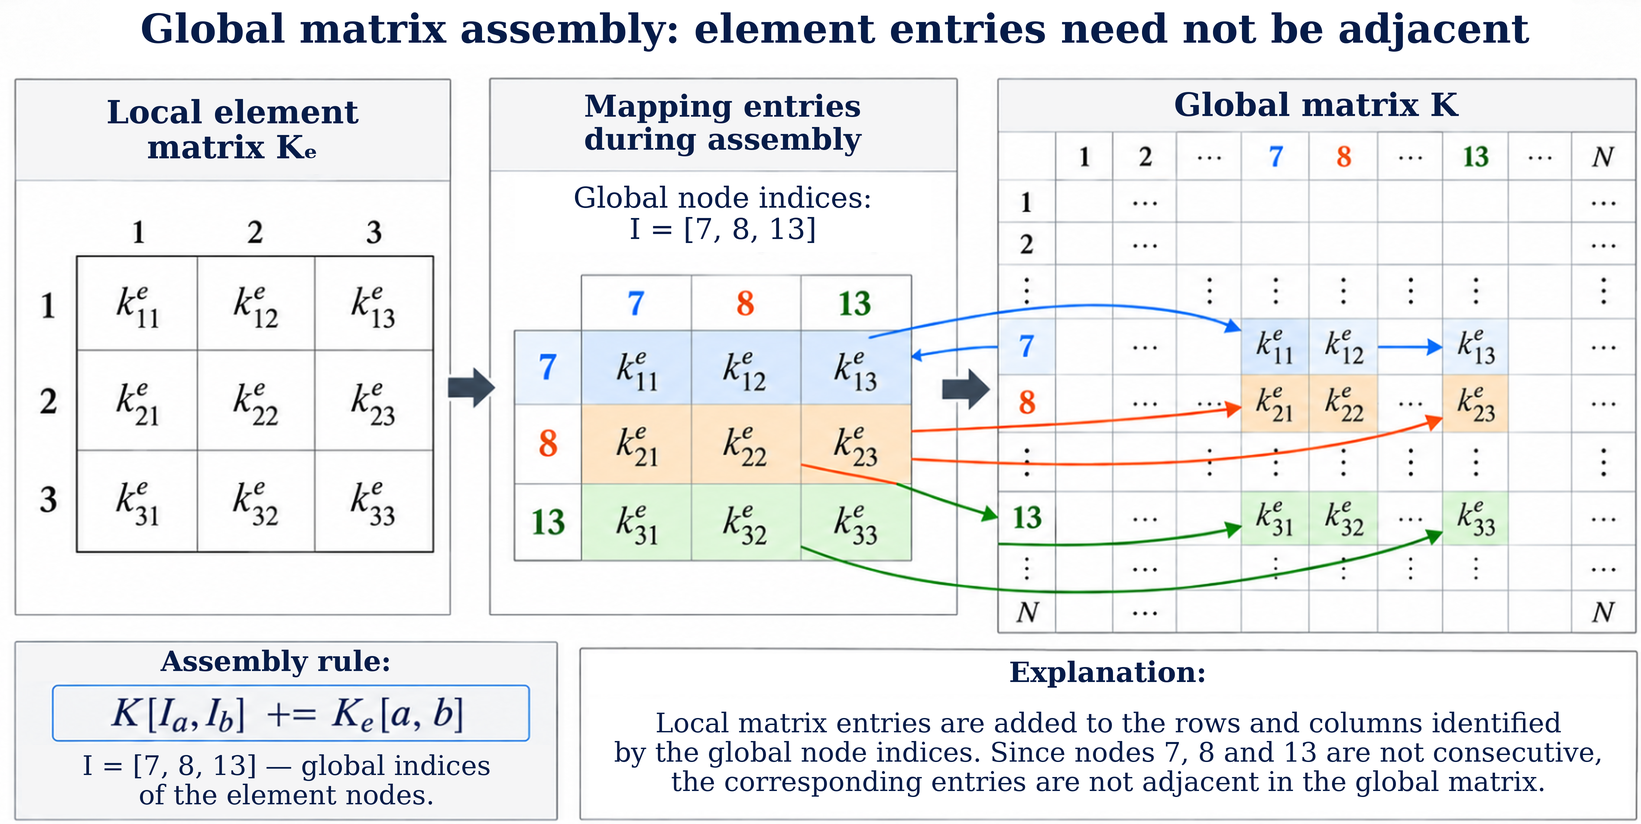


In [15]:
Kglob  = np.zeros([nn, nn])
Fglob = np.zeros(nn)

In [16]:
# Use np.ix_ to select the submatrix associated with these node indices
for el in range(ne):
    IndX =elms[el]
    IndXArr = np.ix_(IndX, IndX)
    Kglob[IndXArr] += get_kel(elms[el], km = lam)    

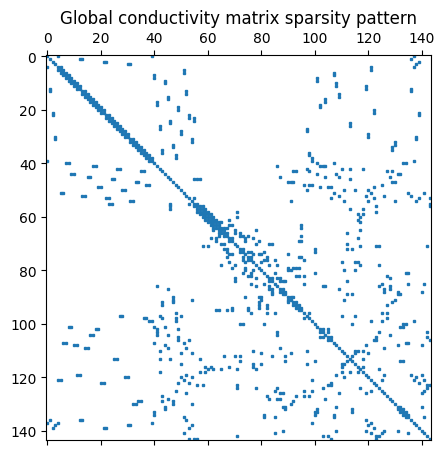

In [17]:
plt.figure(figsize=(5, 5))
plt.spy(Kglob, markersize=2)
plt.title('Global conductivity matrix sparsity pattern')
plt.show()

Only a small proportion of the matrix entries are nonzero. **Sparse matrices**, such as those provided by `scipy.sparse`, are normally used to avoid storing zero entries. Dense storage is retained here because the problem is small. As an exercise, calculate the sum of the entries in each row. How can the result be explained?


## 5. Identification of Boundary Edges

Because the geometry is a simple square, its boundaries can be identified from the node coordinates.

The procedure is as follows:

1. **Identify the boundary nodes:** select nodes whose coordinates lie on the specified side of the plate ($x=0$, $x=L_x$, $y=0$, or $y=L_y$).
2. **Find the adjacent elements:** select triangles with two nodes on the boundary under consideration.
3. **Identify the boundary edges:** for each selected triangle, determine the pair of nodes forming its edge on the plate boundary.
4. **Compute the edge lengths** from the endpoint coordinates.

Boundary edge lengths are required for prescribed heat flux (Neumann conditions) and convection (Robin conditions), because the corresponding terms in the functional are integrated over the plate boundary.


### 5.1. Identification of Boundary Nodes

Select each boundary using its known coordinate.
- $x = 0$ m — **left**
- $y = 0$ m — **bottom**
- $x = 0.005$ m — **right**
- $y = 0.005$ m — **top**

Loop over all mesh nodes and check their coordinates. If the $y$ coordinate is zero, add the node index to `sel_nds`.

**Result:** `sel_nds`, an array containing the global indices of the nodes on the selected boundary.


In [18]:
def sel_nds(pnts, axis='x', value=0):
    coord = 0 if axis == 'x' else 1
    nds = []
    for nd in range(len(pnts)):
        if np.isclose(pnts[nd, coord], value):
            nds.append(nd)
    return np.array(nds, dtype=int)    

### 5.2. Identification of Elements Adjacent to a Boundary

Each triangular finite element has three nodes whose indices are stored in `elms`.

If **two nodes of a triangular element lie on the selected boundary**, the edge joining them is a candidate boundary edge.

Use `np.isin()` to identify these elements by checking whether their nodes belong to `sel_nds`.

The resulting Boolean array contains `True` for boundary nodes and `False` otherwise. Summing these values gives the number of boundary nodes in each element.

**Result:** `sel_elms`, an array containing the indices of elements with exactly two nodes on the selected boundary.


In [19]:
def sel_elms(elms, sel_nds):
    sel_elms = []
    for el in range(ne):
        n = np.isin(elms[el], sel_nds).sum()
        if n == 2:
            sel_elms.append(el)
    return np.array(sel_elms, dtype=int) 

### 5.3. Construction of the Boundary Edge Array

Applying Neumann and Robin boundary conditions requires not only the boundary nodes but also information about which pairs are connected by element edges.

For each element in `sel_elms`, select the two nodes that belong to `sel_nds`.

These two nodes define a boundary edge.

**Result:** a two-dimensional array `edges`, with each row containing the indices of the two nodes of one boundary edge:

$$
\mathrm{edges} =
\begin{pmatrix}
i_1 & j_1 \\
i_2 & j_2 \\
\vdots & \vdots \\
i_m & j_m
\end{pmatrix}
$$

Here, $m$ is the number of identified boundary edges.

The ordering of edges in the array does not affect the subsequent calculation of their lengths or the application of standard scalar heat conduction boundary conditions.


In [20]:
def sel_edges(elms, sel_elms, sel_nds):
    edges = []
    for el in sel_elms:
        edge = elms[el][np.isin(elms[el], sel_nds)]
        edges.append(edge)
    return np.array(edges, dtype=int) 


### 5.4. Boundary Edge Lengths and Boundary Data

For Neumann and Robin conditions, the length of each boundary edge is required because the thermal load is obtained by integration over the corresponding boundary segment.

The length of an edge joining nodes $i$ and $j$ is determined from their coordinates:

$$
L_{ij}=\sqrt{(x_j-x_i)^2+(y_j-y_i)^2}.
$$

The distance is computed using `np.linalg.norm()`, which returns the Euclidean norm of the difference between the node coordinate vectors.

Four arrays are obtained for each side of the plate:

- `nodes` — indices of the boundary nodes;
- `elements` — indices of finite elements with an edge on this boundary;
- `edges` — pairs of node indices defining the boundary edges;
- `L` — corresponding edge lengths, in the same order as the rows of `edges`.

Rather than store these data in separate variables for each side, combine them in the **`boundary` dictionary**.

Each dictionary key (`left`, `right`, `bottom`, or `top`) refers to the data for one boundary: nodes, elements, edges, and edge lengths.

For example, after constructing the dictionary:

- `boundary['bottom']['nodes']` contains the bottom boundary nodes;
- `boundary['bottom']['edges']` contains the bottom boundary edges;
- `boundary['bottom']['length']` contains their lengths.

The `boundary` dictionary therefore combines the geometric and topological data required to impose boundary conditions on each side of the plate.


In [21]:
boundary = {}

for name, axis, value in [
    ('left',   'x', 0),
    ('right',  'x', 5*1e-3),
    ('bottom', 'y', 0),
    ('top',    'y', 5*1e-3)
]:
    nodes = sel_nds(pnts, axis, value)
    elements = sel_elms(elms, nodes)
    edges = sel_edges(elms, elements, nodes)
    
    L = []
    for nd1, nd2 in edges:
        L.append(np.linalg.norm(pnts[nd2] - pnts[nd1]))
    L = np.array(L)
    
    boundary[name] = {
        'nodes': nodes,
        'elements': elements,
        'edges': edges,
        'length': L
    }
boundary

Out[21]: 
{'left': {'nodes': array([ 0,  1,  4,  5,  6,  7,  8,  9, 10, 11, 12]),
  'elements': array([ 80, 101, 102, 103, 105, 106, 162, 163, 186, 189]),
  'edges': array([[ 9,  8],
         [ 6,  5],
         [ 7,  6],
         [ 8,  7],
         [10,  9],
         [11, 10],
         [ 5,  4],
         [12, 11],
         [ 4,  0],
         [ 1, 12]]),
  'length': array([0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005,
         0.0005, 0.0005])},
 'right': {'nodes': array([ 2,  3, 22, 23, 24, 25, 26, 27, 28, 29, 30]),
  'elements': array([ 44,  86,  87,  88,  89,  90, 148, 159, 183, 184]),
  'edges': array([[28, 27],
         [23, 22],
         [24, 23],
         [25, 24],
         [27, 26],
         [29, 28],
         [26, 25],
         [30, 29],
         [22,  2],
         [ 3, 30]]),
  'length': array([0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005,
         0.0005, 0.0005])},
 'bottom': {'nodes': array([ 1,  2, 13, 14, 15, 16, 17, 18, 19, 20, 21]),
 

Plot the identified boundaries.


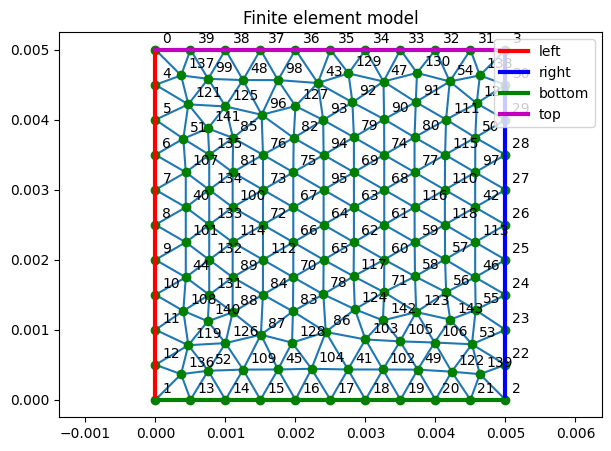

In [22]:
colors = ['r', 'b', 'g', 'm']
fig, ax = plt.subplots(figsize=(7,5))
plt.title('Finite element model')
ax.triplot(pnts[:,0]  , pnts[:,1]  , elms)
ax.plot(pnts[:,0], pnts[:,1], 'go', lw=1.0)
texts = [ax.text(pnts[i,0]+1e-4, pnts[i,1]+1e-4, '%s' %i) for i in range(nn)]
for i, bc in enumerate(boundary):
    edges = boundary[bc]['edges']
    plt.plot(pnts[edges, 0].T, pnts[edges, 1].T, color=colors[i], lw=3)
    plt.plot([], [], color=colors[i], lw=3, label=bc)
plt.axis('equal')
plt.legend(loc='upper right')
plt.show()


## 6. Dirichlet Boundary Conditions: Prescribed Temperature

**Dirichlet boundary conditions (first kind)** specify the temperature on a portion of the plate boundary:

$$
T|_{\Gamma_1}=T_{\Gamma},
$$

where $T_{\Gamma}$ is the prescribed temperature and $\Gamma_1$ is the corresponding boundary segment.

Only the **indices of the nodes** on the selected boundary are required to impose Dirichlet conditions. Boundary edge lengths are not needed.

Assembly of the global conductivity matrix gives the system of linear algebraic equations:

$$
\mathbf K_{\mathrm{glob}}\mathbf T=\mathbf F_{\mathrm{glob}}.
$$

For each boundary node $i$, the following condition must be satisfied:

$$
T_i=T_{\Gamma}.
$$

Unlike Neumann and Robin conditions, a prescribed temperature does not introduce an additional integral term into the functional; it imposes a **constraint on the admissible nodal temperatures**.

Prescribed temperatures are not unknowns of the problem. The stationarity condition is therefore applied only to the free nodal temperatures:

$$
\boxed{
\frac{\partial\Phi}{\partial T_i}=0,
\qquad i\in f,
}
$$

where $f$ is the set of nodes with unknown temperatures.

There are two ways to incorporate prescribed temperatures into the global system.

### Method 1. Equation Replacement at Nodes with Prescribed Temperatures

The simplest approach replaces the equation for each node $i$ with a known temperature.

The steps are:

1. Set all entries in row $i$ of the global conductivity matrix to zero.
2. Set the diagonal entry to $K_{ii}=1$.
3. Set the corresponding right-hand-side entry to $F_i=T_{\Gamma}$.

The equation for the selected node becomes:

$$
1\cdot T_i=T_{\Gamma}.
$$

For example, consider a system of three equations:

$$
\begin{pmatrix}
K_{11}&K_{12}&K_{13}\\
K_{21}&K_{22}&K_{23}\\
K_{31}&K_{32}&K_{33}
\end{pmatrix}
\begin{pmatrix}
T_1\\T_2\\T_3
\end{pmatrix}
=
\begin{pmatrix}
F_1\\F_2\\F_3
\end{pmatrix}
$$

Prescribing $T_1=T_{\Gamma}$ gives:

$$
\begin{pmatrix}
1&0&0\\
K_{21}&K_{22}&K_{23}\\
K_{31}&K_{32}&K_{33}
\end{pmatrix}
\begin{pmatrix}
T_1\\T_2\\T_3
\end{pmatrix}
=
\begin{pmatrix}
T_{\Gamma}\\F_2\\F_3
\end{pmatrix}.
$$

The original equation for the first node is thus replaced by a direct prescription of its temperature. The remaining equations are retained, so the effect of this temperature on adjacent nodes is included automatically.

**Advantage:** simple implementation; the system size remains unchanged.

**Disadvantage:** matrix symmetry is lost because only rows, not the corresponding columns, are modified.

This seminar uses this approach because it preserves the original global node numbering and does not require reducing the matrix dimensions.

### Method 2. Elimination of Prescribed Temperature Degrees of Freedom

An alternative is to substitute the known temperatures directly into the equations and eliminate the corresponding degrees of freedom.

Consider the same system with a prescribed temperature at the first node:

$$
T_1=T_{\Gamma}.
$$

Substitute this value into the remaining two equations:

$$
\begin{cases}
K_{21}T_{\Gamma}+K_{22}T_2+K_{23}T_3=F_2,\\
K_{31}T_{\Gamma}+K_{32}T_2+K_{33}T_3=F_3.
\end{cases}
$$

Move the terms containing the prescribed temperature to the right-hand side:

$$
\begin{cases}
K_{22}T_2+K_{23}T_3=F_2-K_{21}T_{\Gamma},\\
K_{32}T_2+K_{33}T_3=F_3-K_{31}T_{\Gamma}.
\end{cases}
$$

The reduced system is:

$$
\boxed{
\begin{pmatrix}
K_{22}&K_{23}\\
K_{32}&K_{33}
\end{pmatrix}
\begin{pmatrix}
T_2\\T_3
\end{pmatrix}
=
\begin{pmatrix}
F_2-K_{21}T_{\Gamma}\\
F_3-K_{31}T_{\Gamma}
\end{pmatrix}
}
$$

The **row and column** corresponding to the prescribed temperature are removed. Its effect is retained in the right-hand side of the remaining equations.

In general, partition the nodes into two sets:

- $f$ — free nodes, whose temperatures are unknown;
- $c$ — nodes with prescribed temperatures.

The original system can then be written in block form:

$$
\begin{pmatrix}
\mathbf K_{ff}&\mathbf K_{fc}\\
\mathbf K_{cf}&\mathbf K_{cc}
\end{pmatrix}
\begin{pmatrix}
\mathbf T_f\\
\mathbf T_c
\end{pmatrix}
=
\begin{pmatrix}
\mathbf F_f\\
\mathbf F_c
\end{pmatrix}.
$$

Substituting the prescribed temperatures $\mathbf T_c$ gives the system for the free nodes only:

$$
\boxed{
\mathbf K_{ff}\mathbf T_f
=
\mathbf F_f-\mathbf K_{fc}\mathbf T_c
}
$$

This reduced system corresponds directly to stationarity of the functional with respect to the free nodal temperatures.

After solving it, combine the computed free temperatures with the prescribed boundary temperatures to recover the full temperature vector.

**Advantages:** the system size is reduced and matrix symmetry is preserved. For positive thermal conductivity, a connected mesh, and sufficient temperature constraints, the reduced matrix is positive definite.

**Disadvantage:** the free and prescribed node sets must be stored separately; the reduced system must be formed and the full temperature vector reconstructed after solution.

**Important:** when temperatures are prescribed on several boundaries, identify all prescribed-temperature nodes before reducing the system.


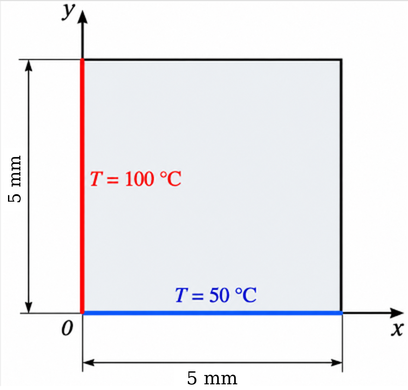


Create copies of the original arrays so that different boundary conditions can be tested.


In [23]:
K1 = Kglob.copy()
F1 = Fglob.copy()

In [24]:
def bc1type(K, F, boundary, T):
    for nd in boundary['nodes']:
        K[nd, :] = 0
        K[nd, nd] = 1
        F[nd] = T
    return K, F    

Apply the boundary conditions and solve the problem.


In [25]:
Tleft   = 100
Tbottom = 50
K1, F1 = bc1type(K1, F1, boundary['left'],   Tleft)
K1, F1 = bc1type(K1, F1, boundary['bottom'], Tbottom)


### Solution of the System of Linear Algebraic Equations

After assembling the global conductivity matrix and applying the boundary conditions, we obtain the linear system:

$$
\mathbf K\mathbf T=\mathbf F,
$$

where $\mathbf K$ is the system matrix, $\mathbf F$ is the thermal load vector, and $\mathbf T$ is the unknown nodal temperature vector.

Two main classes of numerical methods are used to solve linear systems:

- **Direct methods** obtain the solution through a finite sequence of arithmetic operations, subject to round-off error. Examples include Gaussian elimination, LU factorization, and Cholesky factorization. Explicit matrix inversion is not required.
- **Iterative methods** successively improve an approximate solution until a specified tolerance is met. Examples include the Jacobi, Gauss–Seidel, and conjugate gradient methods.

In finite element problems, the global matrix is generally **sparse** because each node is connected to only a limited number of neighboring nodes. Sparse storage reduces memory requirements. In this notebook, however, `Kglob` is stored as a dense NumPy array.

For large systems, direct factorization may introduce additional nonzero entries, known as fill-in, increasing memory and computational costs. Iterative methods avoid full matrix factorization, but their efficiency depends on convergence and system conditioning.

The present system is relatively small, so we use a **direct solver**, `np.linalg.solve()` from NumPy.

This function uses LU factorization to solve the system without explicitly computing the inverse matrix:

```python
T_sol1 = np.linalg.solve(K1, F1)
```

The array `T_sol1` contains the temperature at every mesh node.

For larger finite element models, sparse matrix storage and specialized direct or iterative solvers are preferable.



In [26]:
T_sol1 = np.linalg.solve(K1, F1)

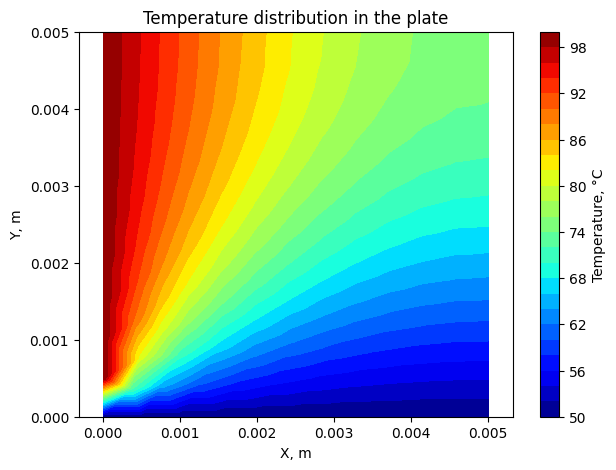

In [27]:
fig, ax = plt.subplots(figsize=(7, 5))

plt.tricontourf(pnts[:, 0], pnts[:, 1], elms, T_sol1,
                levels=30, cmap='jet')

plt.colorbar(label='Temperature, °C')
plt.axis('equal')
plt.xlabel('X, m')
plt.ylabel('Y, m')
plt.title('Temperature distribution in the plate')
plt.show()


## 7. Neumann Boundary Conditions: Prescribed Heat Flux

**Neumann boundary conditions (second kind)** prescribe the heat flux density on a portion of the plate boundary.

Fourier's law is:

$$
\mathbf q=-\lambda\nabla T,
$$

where $\mathbf q$ is the heat flux vector, in W/m², and $\lambda$ is the thermal conductivity.

Here, the Neumann boundary condition is written as:

$$
\boxed{
\lambda\frac{\partial T}{\partial n}=q_{\Gamma}
}
$$

where:

- $q_{\Gamma}$ is the prescribed heat flux density, in W/m²;
- $n$ denotes the outward normal direction;
- $\Gamma_2$ is the boundary segment on which the heat flux is prescribed.

The sign convention is $q_{\Gamma}=-\mathbf q\cdot\mathbf n$: positive $q_{\Gamma}$ denotes heat flow into the plate.

Unlike Dirichlet conditions, a prescribed heat flux does not fix nodal temperatures. Instead, it introduces an **additional thermal load vector** on the right-hand side of the global system.

### Formulation of the Thermal Load Vector

Consider a boundary edge $\Gamma_e$ of length $L$ joining nodes $i$ and $j$.

The contribution of the prescribed heat flux to the functional is:

$$
\Phi_{\Gamma,e}^{(q)}
=
-t\int_{\Gamma_e}q_{\Gamma}T\,dL.
$$

Approximate the temperature along the edge using linear shape functions and the endpoint temperatures:

$$
T=N_iT_i+N_jT_j.
$$

Substitute this expression into the functional, assuming a constant heat flux density $q_{\Gamma}$:

$$
\Phi_{\Gamma,e}^{(q)}
=
-tq_{\Gamma}
\int_{\Gamma_e}
(N_iT_i+N_jT_j)\,dL.
$$

For a linear boundary element, each shape function integrates to half the edge length:

$$
\int_{\Gamma_e}N_i\,dL
=
\int_{\Gamma_e}N_j\,dL
=
\frac{L}{2}.
$$

The shape functions vary linearly from 0 to 1 along the edge, so their mean value is $1/2$.

Therefore:

$$
\boxed{
\Phi_{\Gamma,e}^{(q)}
=
-\frac{q_{\Gamma}tL}{2}(T_i+T_j)
}
$$

### Derivation of the Element Thermal Load Vector

As established above, the finite element equations follow from **stationarity of the functional with respect to the unknown nodal temperatures**.

Differentiate the boundary contribution with respect to the temperatures at nodes $i$ and $j$:

$$
\frac{\partial\Phi_{\Gamma,e}^{(q)}}{\partial T_i}
=
-\frac{q_{\Gamma}tL}{2},
$$

$$
\frac{\partial\Phi_{\Gamma,e}^{(q)}}{\partial T_j}
=
-\frac{q_{\Gamma}tL}{2}.
$$

Combining these derivatives into a vector gives:

$$
\begin{pmatrix}
\dfrac{\partial\Phi_{\Gamma,e}^{(q)}}{\partial T_i}\\[6pt]
\dfrac{\partial\Phi_{\Gamma,e}^{(q)}}{\partial T_j}
\end{pmatrix}
=
-\frac{q_{\Gamma}tL}{2}
\begin{pmatrix}
1\\
1
\end{pmatrix}.
$$

When forming the system of equations, these terms are moved to the right-hand side.

The **element thermal load vector** is therefore:

$$
\boxed{
\mathbf F_{\Gamma,e}
=
\frac{q_{\Gamma}tL}{2}
\begin{pmatrix}
1\\
1
\end{pmatrix}
}
$$

For a constant heat flux density, the boundary edge load is distributed equally between its two nodes.

If the heat flux varies along the edge, the nodal loads will generally differ.

**Because these derivatives do not depend on the unknown nodal temperatures, Neumann conditions contribute only to the right-hand-side vector and do not modify the conductivity matrix.**

The positive sign in $\mathbf F_{\Gamma,e}$ is consistent with the convention that positive heat flux is directed into the plate.

### Incorporation of Neumann Conditions into the Global System

After assembling the global conductivity matrix, the system is:

$$
\mathbf K_{\mathrm{glob}}\mathbf T=\mathbf F_{\mathrm{glob}}.
$$

For each boundary edge $[i,j]$, compute the local thermal load vector:

$$
\mathbf F_{\Gamma,e}=
\begin{pmatrix}
F_{\Gamma,i}\\
F_{\Gamma,j}
\end{pmatrix}.
$$

Add its entries to the corresponding entries of the global vector:

$$
F_i \leftarrow F_i+F_{\Gamma,i},
$$

$$
F_j \leftarrow F_j+F_{\Gamma,j}.
$$

If several edges share a boundary node, their contributions are **summed**.

Neumann conditions therefore modify only the right-hand-side vector $\mathbf F_{\mathrm{glob}}$, not the conductivity matrix $\mathbf K_{\mathrm{glob}}$.

### Special Case: A Thermally Insulated Boundary

If

$$
q_{\Gamma}=0,
$$

then

$$
\mathbf F_{\Gamma,e}=\mathbf 0.
$$

A thermally insulated boundary therefore contributes no additional terms to either the global conductivity matrix or the thermal load vector.

This is a **natural boundary condition** of the variational formulation. Where neither heat flux nor convection is prescribed, thermal insulation is included automatically. A pure Neumann problem also requires heat balance and a temperature normalization to fix the otherwise arbitrary additive constant.

**Important:** fixing one temperature removes the indeterminacy of the temperature level but does not replace the heat balance required for the original pure Neumann problem.


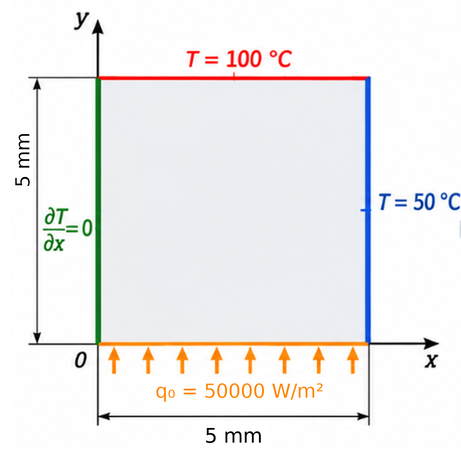


In [28]:
K2 = Kglob.copy()
F2 = Fglob.copy()

Apply the boundary conditions and solve the problem.


In [29]:
def bc2type(F, boundary, q):
    edges = boundary['edges']
    L = boundary['length']
    for nds, length in zip(edges, L):
        F[nds] += q * th * length / 2      
    return F  

In [30]:
q = 50000
F2 = bc2type(F2, boundary['bottom'], q)

In [31]:
Ttop   = 100
Tright = 50
K2, F2 = bc1type(K2, F2, boundary['top'],   Ttop)
K2, F2 = bc1type(K2, F2, boundary['right'], Tright)

In [32]:
T_sol2 = np.linalg.solve(K2, F2)

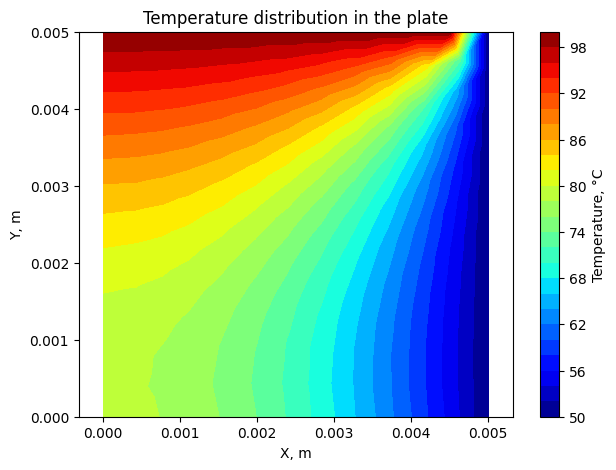

In [33]:
fig, ax = plt.subplots(figsize=(7, 5))

plt.tricontourf(pnts[:, 0], pnts[:, 1], elms, T_sol2,
                levels=30, cmap='jet')

plt.colorbar(label='Temperature, °C')
plt.axis('equal')
plt.xlabel('X, m')
plt.ylabel('Y, m')
plt.title('Temperature distribution in the plate')
plt.show()


## 8. Robin Boundary Conditions: Convective Heat Transfer

**Robin boundary conditions (third kind)** describe heat exchange between the plate surface and surroundings at a known temperature.

According to Newton's law of cooling, the outward heat flux density is:

$$
q_{\mathrm{out}}=\alpha(T-T_{\infty}),
$$

where:

- $\alpha$ is the convective heat transfer coefficient, in W/(m²·K);
- $T$ is the plate surface temperature, in °C;
- $T_{\infty}$ is the ambient temperature, in °C.

Combining this relation with Fourier's law gives the Robin boundary condition:

$$
-\lambda\frac{\partial T}{\partial n}
=
\alpha(T-T_{\infty}),
$$

where $n$ denotes the outward normal direction at the plate surface.

Heat leaves the plate when $T>T_{\infty}$ and enters it from the surroundings when $T<T_{\infty}$.

With the convention that positive heat flux is directed **into the plate**, this becomes:

$$
q_{\mathrm{in}}=\alpha(T_{\infty}-T).
$$

Unlike a Dirichlet condition, a Robin condition does not prescribe the surface temperature; it is determined as part of the solution.

### Formulation of the Boundary Element Matrix and Thermal Load Vector

Consider a boundary edge $\Gamma_e$ of length $L$ joining nodes $i$ and $j$.

The contribution of convection to the functional is:

$$
\Phi_{\Gamma,e}^{(\alpha)}
=
\frac{\alpha t}{2}
\int_{\Gamma_e}(T-T_{\infty})^2\,dL.
$$

Expanding the square gives:

$$
\Phi_{\Gamma,e}^{(\alpha)}
=
\frac{\alpha t}{2}
\int_{\Gamma_e}
\left(T^2-2TT_{\infty}+T_{\infty}^2\right)dL.
$$

Approximate the temperature along the edge using linear shape functions:

$$
T=N_iT_i+N_jT_j.
$$

For constant $\alpha$ and $T_{\infty}$, use the following integrals of the linear shape functions:

$$
\int_{\Gamma_e}N_i\,dL
=
\int_{\Gamma_e}N_j\,dL
=
\frac{L}{2},
$$

$$
\int_{\Gamma_e}N_i^2\,dL
=
\int_{\Gamma_e}N_j^2\,dL
=
\frac{L}{3},
$$

$$
\int_{\Gamma_e}N_iN_j\,dL
=
\frac{L}{6}.
$$

Therefore:

$$
\int_{\Gamma_e}T\,dL
=
\frac{L}{2}(T_i+T_j),
$$

$$
\int_{\Gamma_e}T^2\,dL
=
\frac{L}{3}(T_i^2+T_iT_j+T_j^2).
$$

Substituting these expressions into the functional gives:

$$
\boxed{
\Phi_{\Gamma,e}^{(\alpha)}
=
\frac{\alpha tL}{6}(T_i^2+T_iT_j+T_j^2)
-
\frac{\alpha tLT_{\infty}}{2}(T_i+T_j)
+
\frac{\alpha tLT_{\infty}^2}{2}
}
$$

The final term is independent of the unknown nodal temperatures. Its derivative is therefore zero, and it does not affect the solution.

### Derivation of the Boundary Element Matrix and Load Vector

As established above, the finite element equations follow from **stationarity of the functional with respect to the unknown nodal temperatures**.

Differentiate the boundary contribution with respect to the temperatures at nodes $i$ and $j$:

$$
\frac{\partial\Phi_{\Gamma,e}^{(\alpha)}}{\partial T_i}
=
\frac{\alpha tL}{6}(2T_i+T_j)
-
\frac{\alpha tLT_{\infty}}{2},
$$

$$
\frac{\partial\Phi_{\Gamma,e}^{(\alpha)}}{\partial T_j}
=
\frac{\alpha tL}{6}(T_i+2T_j)
-
\frac{\alpha tLT_{\infty}}{2}.
$$

Combining the derivatives in matrix form gives:

$$
\begin{pmatrix}
\dfrac{\partial\Phi_{\Gamma,e}^{(\alpha)}}{\partial T_i}\\[6pt]
\dfrac{\partial\Phi_{\Gamma,e}^{(\alpha)}}{\partial T_j}
\end{pmatrix}
=
\frac{\alpha tL}{6}
\begin{pmatrix}
2&1\\
1&2
\end{pmatrix}
\begin{pmatrix}
T_i\\
T_j
\end{pmatrix}
-
\frac{\alpha tLT_{\infty}}{2}
\begin{pmatrix}
1\\
1
\end{pmatrix}.
$$

This expression has the form:

$$
\frac{\partial\Phi_{\Gamma,e}^{(\alpha)}}{\partial\{T\}_{\Gamma}}
=
\mathbf K_{\Gamma,e}\{T\}_{\Gamma}
-
\mathbf F_{\Gamma,e}.
$$

The **element convection matrix** is therefore:

$$
\boxed{
\mathbf K_{\Gamma,e}
=
\frac{\alpha tL}{6}
\begin{pmatrix}
2&1\\
1&2
\end{pmatrix}
}
$$

and the **element thermal load vector** is:

$$
\boxed{
\mathbf F_{\Gamma,e}
=
\frac{\alpha tLT_{\infty}}{2}
\begin{pmatrix}
1\\
1
\end{pmatrix}
}
$$

Robin conditions thus contribute both:

- An **element convection matrix** $\mathbf K_{\Gamma,e}$, because the heat flux depends on the unknown surface temperature.
- An **element thermal load vector** $\mathbf F_{\Gamma,e}$, accounting for the known ambient temperature.

These expressions represent the contribution of a boundary edge to the global system. Stationarity is imposed on the **complete plate functional**, after summing the contributions of all finite elements and boundary edges.

### Incorporation of Robin Conditions into the Global System

After assembling the element conductivity matrices, we have:

$$
\mathbf K_{\mathrm{glob}}\mathbf T=\mathbf F_{\mathrm{glob}}.
$$

For each boundary edge $[i,j]$, compute the $2\times2$ matrix $\mathbf K_{\Gamma,e}$ and the two-entry vector $\mathbf F_{\Gamma,e}$.

Add their entries to the corresponding positions in the global matrix and vector:

$$
\begin{pmatrix}
K_{ii}&K_{ij}\\
K_{ji}&K_{jj}
\end{pmatrix}
\leftarrow
\begin{pmatrix}
K_{ii}&K_{ij}\\
K_{ji}&K_{jj}
\end{pmatrix}
+
\mathbf K_{\Gamma,e},
$$

$$
\begin{pmatrix}
F_i\\
F_j
\end{pmatrix}
\leftarrow
\begin{pmatrix}
F_i\\
F_j
\end{pmatrix}
+
\mathbf F_{\Gamma,e}.
$$

If a node belongs to several boundary edges, their contributions are **summed**.

The global system then accounts for both heat conduction within the plate and convection at its boundaries.

**Important:** with the equation-replacement method used in this seminar, Robin contributions must be assembled before applying Dirichlet conditions.

### Properties of Robin Boundary Conditions

1. Unlike Dirichlet conditions, they do not fix the boundary temperature.
2. Unlike prescribed-flux Neumann conditions, the heat flux depends on the unknown surface temperature.
3. For constant $\alpha$ and $T_{\infty}$, the problem remains linear.
4. Robin conditions modify both the global matrix and the right-hand-side vector.
5. As $\alpha$ increases, the surface temperature approaches $T_{\infty}$, provided that all other parameters and boundary conditions remain unchanged.

Robin conditions therefore model heat exchange between the plate and a gas or liquid without prescribing the surface temperature.




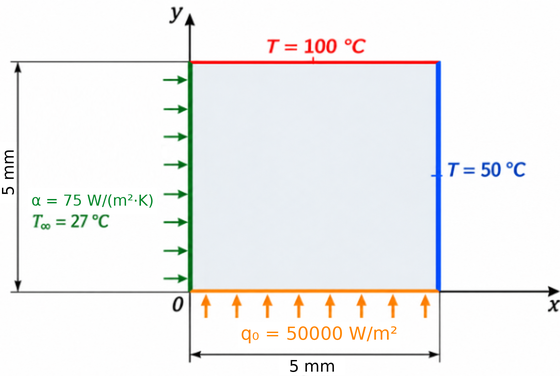


In [34]:
K3 = Kglob.copy()
F3 = Fglob.copy()

Apply the boundary conditions and solve the problem.


In [35]:
def bc3type(K, F, boundary, hinf, Tinf):
    edges = boundary['edges']
    L = boundary['length']
    for nds, length in zip(edges, L):        
        F[nds] += hinf * th * length * Tinf / 2 * np.array( [1,
                                                             1])
        IndXArr = np.ix_(nds, nds)
        K[IndXArr] +=hinf * th * length / 6 * np.array([
                                                [2, 1],
                                                [1, 2]])
    return K, F 

In [36]:
hinf  = 75
Tinf  = 27
K3, F3 = bc3type(K3, F3, boundary['left'], hinf, Tinf)

In [37]:
q = 50000
F3 = bc2type(F3, boundary['bottom'], q)

In [38]:
Ttop   = 100
Tright = 50
K3, F3 = bc1type(K3, F3, boundary['top'],   Ttop)
K3, F3 = bc1type(K3, F3, boundary['right'], Tright)

In [39]:
T_sol3 = np.linalg.solve(K3, F3)

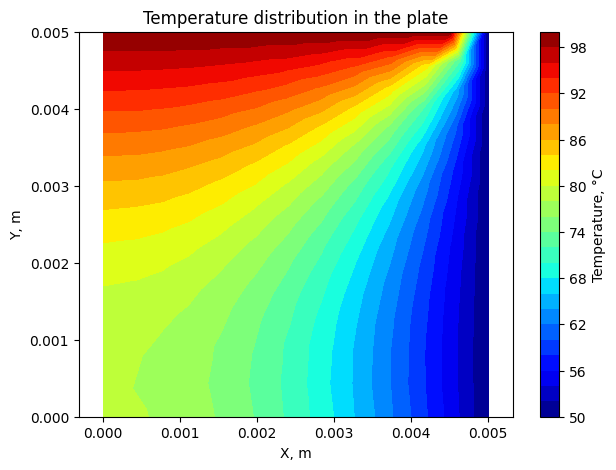

In [40]:
fig, ax = plt.subplots(figsize=(7, 5))

plt.tricontourf(pnts[:, 0], pnts[:, 1], elms, T_sol3,
                levels=30, cmap='jet')

plt.colorbar(label='Temperature, °C')
plt.axis('equal')
plt.xlabel('X, m')
plt.ylabel('Y, m')
plt.title('Temperature distribution in the plate')
plt.show()


## 9. Seminar Summary

In this seminar, we developed a program to compute the **steady-state temperature field in a plate using the finite element method**, with Python, NumPy, and Gmsh.

The main stages of finite element analysis were considered in sequence:

1. **Finite element model generation.** A mesh of linear triangular elements was generated from the geometry, and the node coordinates and element connectivity were extracted.
2. **Element matrix formulation.** The triangular element conductivity matrix was derived from a linear approximation of the temperature field and a variational formulation.
3. **Global assembly.** Element matrices were assembled into the global conductivity matrix using the shared nodes of adjacent elements.
4. **Application of boundary conditions.** Dirichlet, Neumann, and Robin conditions were implemented to represent prescribed temperature, prescribed heat flux, and convection at the plate boundaries.
5. **Solution and visualization.** The resulting linear system was solved numerically, and the nodal temperature field was plotted.

### Main Results

**All three types of boundary conditions are incorporated into a single system of equations**, but their implementations differ:

- **Dirichlet conditions** prescribe nodal temperatures and require modification of the system.
- **Neumann conditions** add contributions to the thermal load vector.
- **Robin conditions** add contributions to both the global matrix and the right-hand-side vector.

All the expressions were derived within a single variational formulation of heat conduction, based on **stationarity of the functional with respect to the unknown nodal temperatures**.
